# Optimization methods from scratch (NumPy)

Gradient descent (batch and mini-batch), momentum, RMSprop and Adam, implemented in `optimizers.py` and used to train the same
small ReLU network on the noisy moons problem. All settings use the same network, learning rate and number of epochs, and every
run is repeated with 5 random seeds (mean ± std).

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!git clone -b feat/optimization-methods https://github.com/nyawmolny/deep-learning-fundamentals/

Cloning into 'deep-learning-fundamentals'...
remote: Enumerating objects: 327, done.
remote: Counting objects: 100% (327/327), done.
remote: Compressing objects: 100% (234/234), done.
remote: Total 327 (delta 76), reused 297 (delta 55), pack-reused 0 (from 0)
Receiving objects: 100% (327/327), 4.19 MiB | 25.40 MiB/s, done.
Resolving deltas: 100% (76/76), done.


In [4]:
%cd deep-learning-fundamentals/02-regularization-and-optimization/optimization/

/content/deep-learning-fundamentals/02-regularization-and-optimization/optimization


In [5]:
!ls

data.py  model.py  optimizers.py  test_optimizers.py  test_torch.py


In [6]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from data import make_moons_dataset, plot_decision_boundary
from model import predict, train
from optimizers import Adam, GradientDescent, Momentum, RMSprop

SEEDS = range(5)
DIMS = [2, 10, 5, 1]
LR, EPOCHS, BATCH = 0.01, 100, 64

In [7]:
DRIVE_ASSETS = Path("/content/drive/MyDrive/data/02-regularization-and-optimization/optimization/assets")
LOCAL_ASSETS = Path("./assets")

ASSETS = DRIVE_ASSETS if Path("/content/drive/MyDrive").exists() else LOCAL_ASSETS
ASSETS.mkdir(parents=True, exist_ok=True)
print("Saving assets to:", ASSETS.resolve())

Saving assets to: /content/drive/MyDrive/data/02-regularization-and-optimization/optimization/assets


## 1. Data

train: 2000 | test: 1000


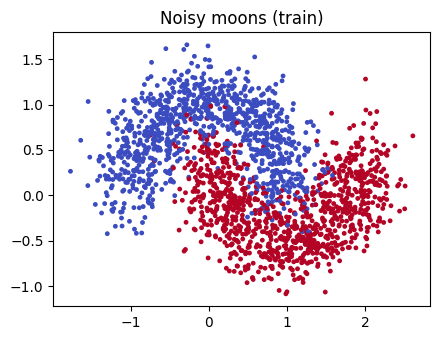

In [8]:
X_tr, Y_tr = make_moons_dataset(2000, noise=0.25, seed=0)
X_te, Y_te = make_moons_dataset(1000, noise=0.25, seed=1)
print("train:", X_tr.shape[1], "| test:", X_te.shape[1])

fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.scatter(X_tr[0], X_tr[1], c=Y_tr.ravel(), s=6, cmap="coolwarm")
ax.set_title("Noisy moons (train)")
plt.tight_layout()
plt.savefig(ASSETS / "moons_data.png", dpi=150)
plt.show()

## 2. Comparison at the same learning rate

Batch gradient descent makes one update per epoch, mini-batches make about 32 (2000 / 64), so batch GD is also run for the
same number of updates as the mini-batch methods.

In [9]:
updates_per_epoch = math.ceil(X_tr.shape[1] / BATCH)
configs = {
    "batch GD": (lambda: GradientDescent(LR), None, EPOCHS),
    "batch GD (same number of updates)": (lambda: GradientDescent(LR), None, EPOCHS * updates_per_epoch),
    "mini-batch GD": (lambda: GradientDescent(LR), BATCH, EPOCHS),
    "momentum (beta=0.9)": (lambda: Momentum(LR, 0.9), BATCH, EPOCHS),
    "RMSprop (beta=0.9)": (lambda: RMSprop(LR, 0.9), BATCH, EPOCHS),
    "Adam": (lambda: Adam(LR), BATCH, EPOCHS),
}


def acc(params, X, Y):
    return float(np.mean(predict(params, X) == Y))


def pm(v):
    return f"{100 * np.mean(v):.1f} ± {100 * np.std(v):.1f}"


results = {}
for name, (make_opt, bs, epochs) in configs.items():
    rows, curves = [], []
    for s in SEEDS:
        params, costs = train(X_tr, Y_tr, DIMS, make_opt(), epochs, bs, seed=s)
        rows.append((acc(params, X_tr, Y_tr), acc(params, X_te, Y_te), costs[-1]))
        curves.append(costs)
    results[name] = (np.array(rows), np.mean(curves, axis=0), 1 if bs is None else updates_per_epoch)

print(f"{'optimizer':<36} | updates | train acc | test acc | final cost")
for name, (rows, curve, per_epoch) in results.items():
    print(f"{name:<36} | {len(curve) * per_epoch:>7} | {pm(rows[:, 0])} | {pm(rows[:, 1])} | {rows[:, 2].mean():.3f}")

optimizer                            | updates | train acc | test acc | final cost
batch GD                             |     100 | 62.3 ± 21.3 | 61.5 ± 20.3 | 0.612
batch GD (same number of updates)    |    3200 | 88.7 ± 0.9 | 88.3 ± 0.8 | 0.271
mini-batch GD                        |    3200 | 88.8 ± 0.8 | 88.3 ± 0.8 | 0.272
momentum (beta=0.9)                  |    3200 | 88.7 ± 0.8 | 88.1 ± 0.9 | 0.272
RMSprop (beta=0.9)                   |    3200 | 94.7 ± 0.3 | 93.5 ± 0.5 | 0.138
Adam                                 |    3200 | 94.9 ± 0.1 | 93.7 ± 0.2 | 0.136


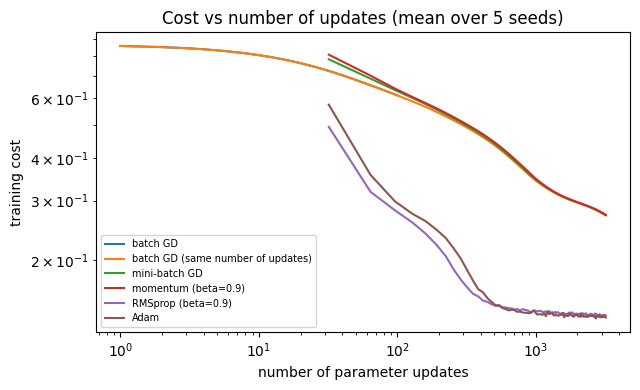

In [ ]:
plt.figure(figsize=(6.5, 4))
for name, (rows, curve, per_epoch) in results.items():
    plt.plot(np.arange(1, len(curve) + 1) * per_epoch, curve, label=name)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("number of parameter updates")
plt.ylabel("training cost")
plt.legend(fontsize=7)
plt.title("Cost vs number of updates (mean over 5 seeds)")
plt.tight_layout()
plt.savefig(ASSETS / "cost_curves.png", dpi=150)
plt.show()

## 3. Sensitivity to the learning rate (mini-batches, 100 epochs)

In [15]:
lrs = [0.003, 0.01, 0.03, 0.1, 0.3]
sweep = {}
for name, make in {"mini-batch GD": lambda lr: GradientDescent(lr), "Adam": lambda lr: Adam(lr)}.items():
    for lr in lrs:
        sweep[(name, lr)] = np.array([
            acc(train(X_tr, Y_tr, DIMS, make(lr), EPOCHS, BATCH, seed=s)[0], X_te, Y_te) for s in SEEDS
        ])

print("test accuracy (mean ± std over 5 seeds)")
print(f"{'lr':<6} | {'mini-batch GD':<14} | Adam")
for lr in lrs:
    print(f"{lr:<6} | {pm(sweep[('mini-batch GD', lr)]):<14} | {pm(sweep[('Adam', lr)])}")

test accuracy (mean ± std over 5 seeds)
lr     | mini-batch GD  | Adam
0.003  | 84.7 ± 1.6     | 94.0 ± 0.1
0.01   | 88.3 ± 0.8     | 93.7 ± 0.2
0.03   | 92.9 ± 0.8     | 93.5 ± 0.5
0.1    | 93.4 ± 0.4     | 93.1 ± 0.4
0.3    | 93.1 ± 0.9     | 92.5 ± 0.9


## 4. Decision boundaries (seed 0)

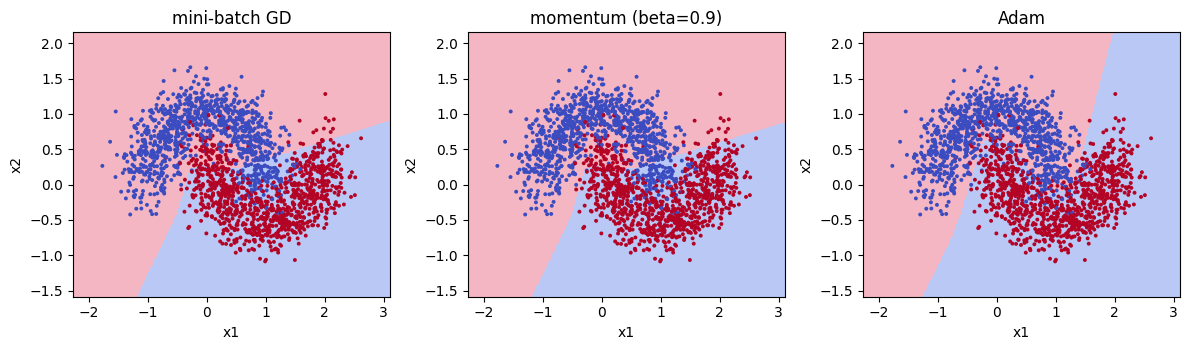

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, name in zip(axes, ["mini-batch GD", "momentum (beta=0.9)", "Adam"]):
    make_opt, bs, epochs = configs[name]
    params, _ = train(X_tr, Y_tr, DIMS, make_opt(), epochs, bs, seed=0)
    plot_decision_boundary(lambda Z, p=params: predict(p, Z), X_tr, Y_tr, ax, name)
plt.tight_layout()
plt.savefig(ASSETS / "decision_boundaries.png", dpi=150)
plt.show()

## 5. Results and notes

- **Batch GD vs mini-batch GD:** batch GD with 100 updates is far behind (61.5% test, std 20.3) because it makes 32 times fewer updates at the same learning rate and has not converged. With the same 3200 updates, batch GD and mini-batch GD are indistinguishable (88.3% test for both). On this problem mini-batching gives more updates per epoch, not better final accuracy.
- **Momentum vs mini-batch GD:** no difference (88.1% vs 88.3% test, same final cost 0.272). Probably the problem is simple enough that momentum has little to add, but I did not test this.
- **RMSprop and Adam vs mini-batch GD at lr 0.01:** both are clearly better (93.5% and 93.7% vs 88.3% test, the intervals do not overlap). RMSprop and Adam cannot be told apart.
- **Learning rate:** the two methods reach similar accuracy, but at different learning rates. Adam is already at 94.0% test with lr 0.003, where mini-batch GD (84.7%) has not converged, while mini-batch GD reaches 93.4% only at lr 0.1. For lr from 0.003 to 0.1 the mean test accuracy of Adam stays between 93.1% and 94.0% (it falls to 92.5% at 0.3). So Adam widens the range of learning rates that work; it does not clearly raise the best achievable accuracy (the best mean of Adam is 0.6 pp higher than that of mini-batch GD, on a coarse grid of five learning rates).
- **Which differences are real:** a difference counts as real when the mean ± std intervals over 5 seeds do not overlap. Real: Adam vs mini-batch GD at lr 0.003 and 0.01, RMSprop vs mini-batch GD at lr 0.01, and batch GD at 100 updates (which only shows under-training). Not distinguishable: batch GD vs mini-batch GD at equal updates, momentum vs plain GD, Adam vs RMSprop, and GD vs Adam from lr 0.03 upward. With 5 seeds this is a rough criterion.